# Wine Quality Lab: experiment review

Estimate the sensory quality of a Portuguese red wine from eleven laboratory measurements. The engineering goal is a small, inspectable regression pipeline that improves on predicting the mean score and prevents repeated measurements from inflating evaluation results.

This notebook inspects the committed experiment. Run `python -m wine_quality train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: random_forest_leaf5
Split: {'train': 1087, 'test': 272, 'method': 'feature-group holdout + 5-fold grouped CV'}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test"]).T
display(comparison)

,mae,rmse,r2
mean_baseline,0.718491,0.858089,-0.027378
scaled_ridge,0.554935,0.721501,0.273662
random_forest_leaf2,0.534133,0.690410,0.334912
random_forest_leaf5,0.536648,0.691386,0.333030


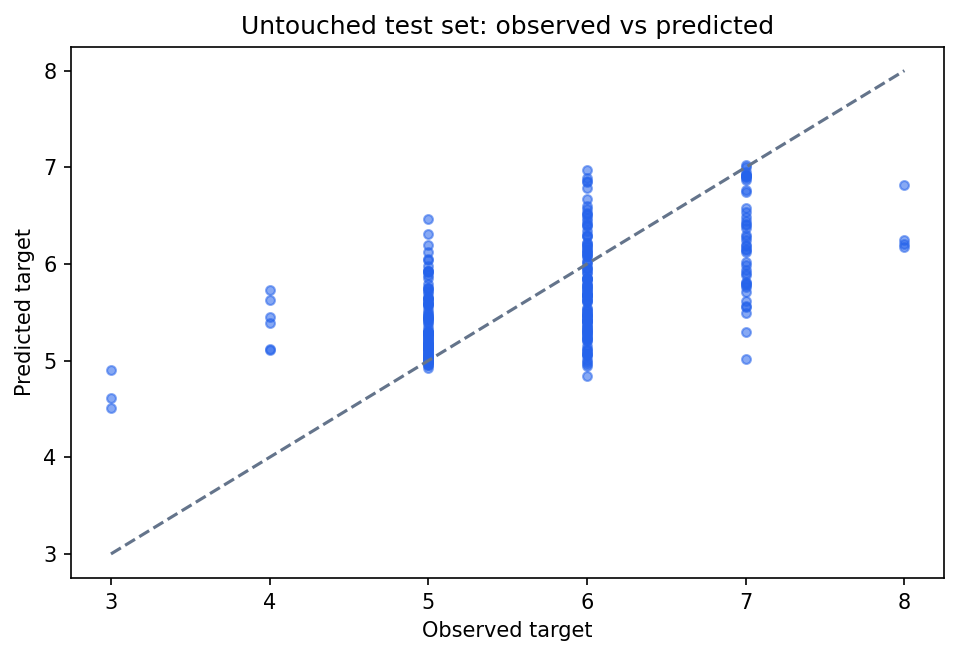

In [3]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

The forest with leaf size 5 was selected by training CV. The leaf-size-2 forest has slightly lower test MAE, but the selection stays unchanged. That difference is a useful example of why test results must not decide hyperparameters. Quality is an ordinal sensory judgment, and a fractional regression estimate is not a certification.

## Where they stop

One regional wine population and a small dataset limit external validity. No vineyard, batch, or vintage identifiers are available to validate unseen producers or future vintages. Grouping identical measurements removes a specific leakage route; it does not establish independence between all samples. Permutation importance describes this fitted model and holdout, not causal effects.